# Same-Camera and Cross-Camera Vehicle Association

Explore simple rules for associating a motorcycle observed at a traffic camera with a candidate observation from a rear-view camera. Same-camera processing should preserve the tracker identity. Cross-camera association is more difficult because tracker IDs are local to each camera.

The data below is synthetic and demonstrates scoring only. It is not evidence of real cross-camera matching performance.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Illustrative traffic-camera event and rear-camera track candidates.
# Appearance vectors stand in for normalized visual descriptors.
traffic_event = {"event_id": "event-01", "time_sec": 12.0, "appearance": [0.80, 0.50, 0.20]}
rear_candidates = [
    {"track_id": "rear-01", "times_sec": [14.5, 15.0, 15.5], "appearance": [0.78, 0.52, 0.19]},
    {"track_id": "rear-02", "times_sec": [16.0, 16.5], "appearance": [0.20, 0.80, 0.55]},
    {"track_id": "rear-03", "times_sec": [22.0, 22.5], "appearance": [0.75, 0.48, 0.25]},
]
MIN_TRAVEL_SEC = 1.0
MAX_TRAVEL_SEC = 8.0
MIN_SIMILARITY = 0.80
MIN_SCORE_MARGIN = 0.08

## Explore temporal and appearance compatibility

A candidate is considered only when its observation time falls within a plausible travel-time window. Appearance similarity is then estimated using cosine similarity. Real camera changes, lighting, viewpoint, occlusion, and vehicle motion can make appearance descriptors unreliable.

In [2]:
def cosine_similarity(a, b):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    denom = np.linalg.norm(a) * np.linalg.norm(b)
    
    if denom == 0:
        return 0.0
    
    return float(np.dot(a, b) / denom)

def score_candidates(event, candidates, min_travel, max_travel):
    rows = []
    for candidate in candidates:
        times = candidate["times_sec"]
        # Use the earliest rear-camera observation as the initial travel-time estimate.
        travel = min(times) - event["time_sec"]
        temporal_ok = min_travel <= travel <= max_travel
        similarity = cosine_similarity(event["appearance"], candidate["appearance"])
        
        rows.append({"track_id": candidate["track_id"], "travel_time_sec": travel,
                     "temporal_ok": temporal_ok, "appearance_similarity": similarity,
                     "eligible": temporal_ok})
    
    return pd.DataFrame(rows).sort_values("appearance_similarity", ascending=False).reset_index(drop=True)

scores = score_candidates(traffic_event, rear_candidates, MIN_TRAVEL_SEC, MAX_TRAVEL_SEC)
display(scores)

,track_id,travel_time_sec,temporal_ok,appearance_similarity,eligible
0,rear-01,2.5,True,0.999546,True
1,rear-03,10.0,False,0.997847,False
2,rear-02,4.0,True,0.700918,True


## Visualize candidate scores

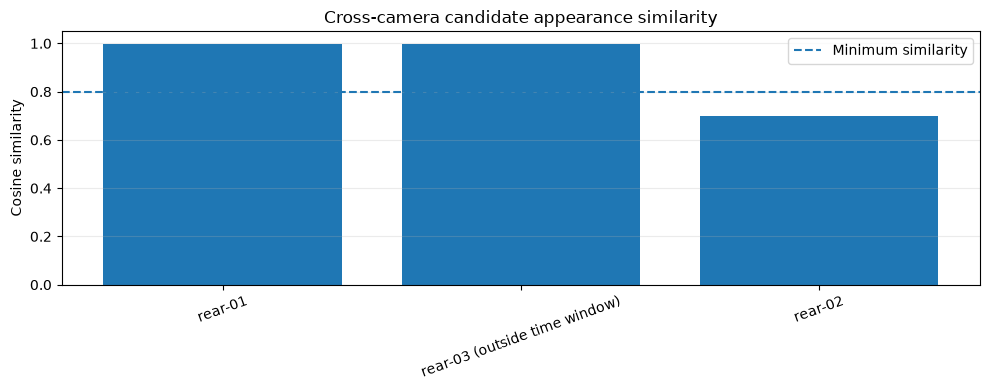

In [3]:
plot_data = scores.copy()
plot_data["label"] = plot_data["track_id"] + np.where(plot_data["eligible"], "", " (outside time window)")

plt.figure(figsize=(10, 4))
plt.bar(plot_data["label"], plot_data["appearance_similarity"])
plt.axhline(MIN_SIMILARITY, linestyle="--", label="Minimum similarity")
plt.ylim(0, 1.05)
plt.ylabel("Cosine similarity")
plt.title("Cross-camera candidate appearance similarity")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

## Apply a cautious matching and abstention rule

The experiment selects a match only when the best candidate is inside the time window, exceeds the similarity threshold, and is sufficiently separated from the next eligible candidate. Otherwise it abstains rather than forcing an identity match.

In [4]:
def choose_match(score_table):
    eligible = score_table[score_table["eligible"]].sort_values("appearance_similarity", ascending=False)
    
    if eligible.empty:
        return {"status": "ABSTAIN", "matched_track_id": None, "reason": "no candidate inside travel-time window"}
    
    best = eligible.iloc[0]
    second_score = float(eligible.iloc[1]["appearance_similarity"]) if len(eligible) > 1 else 0.0
    margin = float(best["appearance_similarity"] - second_score)
    
    if best["appearance_similarity"] < MIN_SIMILARITY:
        return {"status": "ABSTAIN", "matched_track_id": None, "reason": "best appearance score below threshold"}
    
    if len(eligible) > 1 and margin < MIN_SCORE_MARGIN:
        return {"status": "ABSTAIN", "matched_track_id": None, "reason": "top candidates are ambiguous", "top_margin": margin}
    
    return {"status": "MATCH_CANDIDATE", "matched_track_id": best["track_id"],
            "reason": "time and appearance checks passed", "top_margin": margin}

print(choose_match(scores))

{'status': 'MATCH_CANDIDATE', 'matched_track_id': 'rear-01', 'reason': 'time and appearance checks passed', 'top_margin': 0.29862791385108534}
